# Exercício

1. Gere uma amostra de tamanho $M$ de uma exponencial através do método de inversão visto em sala. Compare com uma exponencial gerada pelo numpy via histogramas. Comparem também com a densidade real da exponencial $f(x) = \lambda e^{-\lambda x}$ (isto é, seu histograma normalizado tem que ficar igual essa curva).

2. Agora considere $T_n = X_n / n$ onde $X_n$ é uma Geométrica com parâmetro $\lambda/n$. Mostre que quando $n$ é grande, isso se aproxima de uma exponencial.

3. Considere agora $X_1, X_2, \ldots$ variáveis aleatórias i.i.d. com distribuição Exponencial de parâmetro $\lambda$. Vá somando essas variáveis até que a soma ultrapasse $1$ e conte quantas delas foram somadas antes de ultrapassar $1$. Repita esse procedimento $M$ vezes e mostre empiricamente que essa quantidade segue aproximadamente uma Poisson de parâmetro $\lambda$. Compare o histograma obtido com uma Poisson gerada pelo numpy e com a função de probabilidade real da Poisson.

# exercicio 1 

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 

In [3]:
N = 1000
p = 0.5
U = np.random.uniform(0, 1, size = N)

In [4]:
lam = 5
x = []
U = np.random.uniform(0,1,size = N)
for u in U:
    a = -np.log(1-u)/lam
    x.append(a)

(array([606., 245.,  84.,  38.,  16.,   5.,   2.,   3.,   0.,   1.]),
 array([1.61111888e-04, 1.85823723e-01, 3.71486335e-01, 5.57148947e-01,
        7.42811558e-01, 9.28474170e-01, 1.11413678e+00, 1.29979939e+00,
        1.48546200e+00, 1.67112462e+00, 1.85678723e+00]),
 <BarContainer object of 10 artists>)

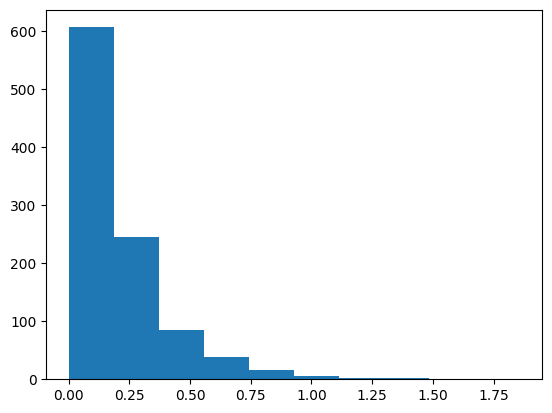

In [5]:
plt.hist(x)

(array([519., 262., 111.,  55.,  28.,  15.,   5.,   3.,   0.,   2.]),
 array([3.07247945e-04, 1.48613499e-01, 2.96919750e-01, 4.45226001e-01,
        5.93532251e-01, 7.41838502e-01, 8.90144753e-01, 1.03845100e+00,
        1.18675725e+00, 1.33506351e+00, 1.48336976e+00]),
 <BarContainer object of 10 artists>)

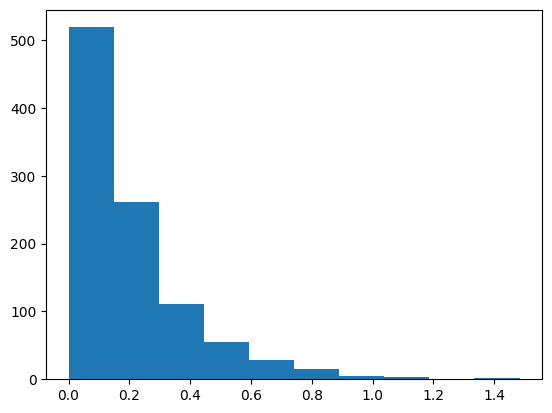

In [6]:
b = np.random.exponential(1/lam, size = N)
plt.hist(b)

(array([3.12101911, 1.34819533, 0.50955414, 0.1910828 , 0.09023355,
        0.03715499, 0.        , 0.        , 0.        , 0.01061571]),
 array([1.0000e-03, 1.8940e-01, 3.7780e-01, 5.6620e-01, 7.5460e-01,
        9.4300e-01, 1.1314e+00, 1.3198e+00, 1.5082e+00, 1.6966e+00,
        1.8850e+00]),
 <BarContainer object of 10 artists>)

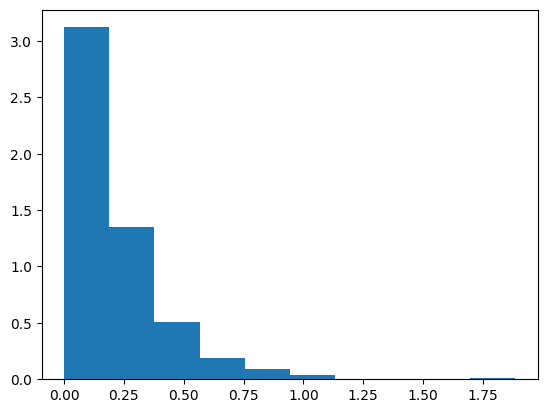

In [7]:
U = np.random.uniform(0,1, size = N)
x = []
for u in U:
    g = np.ceil(np.log(1-u)/np.log(1-lam/N))
    x.append(g/N)
plt.hist(x, density = True)



(array([541., 238., 121.,  57.,  25.,  10.,   5.,   0.,   2.,   1.]),
 array([1.0000e+00, 1.5850e+02, 3.1600e+02, 4.7350e+02, 6.3100e+02,
        7.8850e+02, 9.4600e+02, 1.1035e+03, 1.2610e+03, 1.4185e+03,
        1.5760e+03]),
 <BarContainer object of 10 artists>)

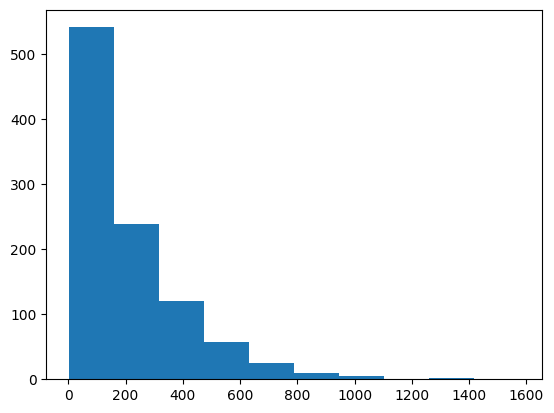

In [8]:
a = np.random.geometric(lam/N, size = 1000)
plt.hist(a)

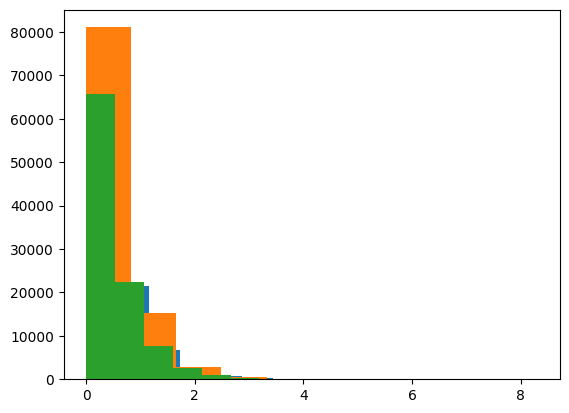

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
lam = 2
M = 100000
n_values = [20, 100, 500]

for n in n_values:
    p = lam / n
    U = np.random.uniform(0, 1, M)
    X = np.floor(np.log1p(-U) / np.log1p(-p)) + 1
    Tn = X / n

    U_exp = np.random.uniform(0, 1, M)
    amostra_exp = -np.log1p(-U_exp) / lam
    plt.hist(amostra_exp)

(array([1.3570e+04, 2.7311e+04, 2.7069e+04, 1.7959e+04, 8.8260e+03,
        3.6400e+03, 1.1790e+03, 3.3400e+02, 9.0000e+01, 2.2000e+01]),
 array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.]),
 <BarContainer object of 10 artists>)

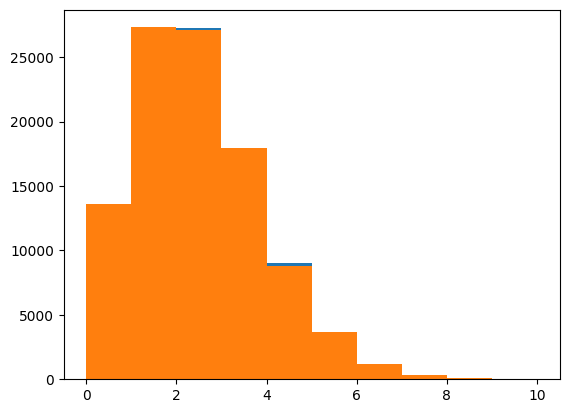

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
lam = 2
M = 100000
contagens = np.zeros(M)

for repeticao in range(M):
    soma = 0.0
    quantidade = 0

    while True:
        U = np.random.uniform(0, 1)
        x = -np.log1p(-U) / lam

        if soma + x > 1:
            break

        soma += x
        quantidade += 1

    contagens[repeticao] = quantidade

plt.hist(contagens)
plt.hist(np.random.poisson(lam=lam, size=M))